## Module 3: Computational Drug Discovery Project Template

Complete the sections below as a team. Remove the word “Template” only if it appears in the final notebook title.

## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  
The below sections should be addressed in your Project Report as a Jupyter notebook, based on Module3_Project_Template.ipynb. All groups submit a Project Report, only those in the Sullivan Company have Oral Presentations (**all due 11/17**).

## Disease Background: 

Obesity is a chronic disease influenced by genetic, hormonal, environmental, and behavioral factors that affect appetite, metabolism, and fat storage. In 2022, about one in eight people worldwide lived with obesity, showing how substantial obesity is ([WHO](https://www.who.int/news/item/01-03-2024-one-in-eight-people-are-now-living-with-obesity)). In adults, obesity is classified as a body mass index (BMI) of at least 30 kg/m² and increases the risk of type 2 diabetes, cardiovascular disease, and several cancers ([WHO](https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight)). As discussed in Module 3 Lecture 1, altered signaling between the gut, brain, pancreas, and adipose tissue can disrupt fullness and glucose regulation. GLP-1 receptor agonists, such as semaglutide, target these pathways to support appetite control and weight loss. Treatment includes nutrition and physical activity changes, medications, and metabolic surgery. 

## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

### Task 1a: Model and fitting method
We adapted the instructor's `fit_semaglutide_GLP1R.py` example, keeping its brute-force search and `curve_fit` approach. The only additional analysis is an approximate 95% confidence interval for Cavalitide Kd.

The model assumes GLP1 and Cavalitide compete for one receptor binding site at equilibrium, and that either ligand fully activates the receptor. GLP1 is fixed at the example's fasting concentration, 0.015 nM, with Kd = 0.17 nM. Free ligand concentrations are approximated by the supplied concentrations. Only Cavalitide Kd is fitted. All 12 observations receive equal weight. The 0.38 nM semaglutide value is the instructor's reference.

### Task 1b: Fit and plot


Brute-force Kd2 = 0.074 nM (SSE = 0.0054)
Fitted Kd2 = 0.077 nM (SSE = 0.0052)
Kd standard error = 0.00454 nM
Approximate 95% confidence interval = [0.06806, 0.08587] nM


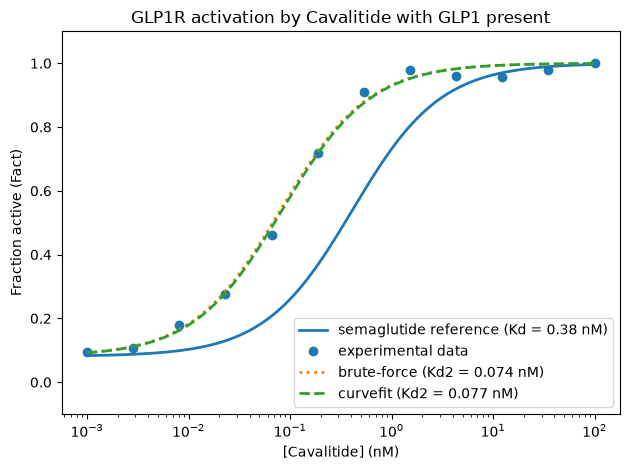

In [ ]:
%matplotlib inline
# fit_cavalitide_GLP1R.py
# Adapted from the instructor's fit_semaglutide_GLP1R.py example.

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM]
Kd1 = 0.17 # L1, GLP1
Kd2 = 0.38 # semaglutide reference
L1 = 0.015 # [nM] GLP1 (fasting)
L2 = np.logspace(-3, 2, 500) # [nM] semaglutide or cavalitide

# Load the data
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)
L2_loaded, Fact_loaded = data[:, 0], data[:, 1]

# Approach 1: Brute force optimization of Kd2. try many candidate values in a for loop
Kd2_candidates = np.logspace(-3, 2, 100) # [nM]
SSE_brute = np.inf
for Kd2_try in Kd2_candidates:
    # Sum of squared errors between the data and the model for this candidate
    SSE = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_try))**2)
    if SSE < SSE_brute:
        SSE_brute = SSE
        Kd2_brute = Kd2_try
print(f"Brute-force Kd2 = {Kd2_brute:.3f} nM (SSE = {SSE_brute:.4f})")

# Approach 2: Python curvefit of Kd2. related to steepest descent method
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
                       L2_loaded, Fact_loaded, p0=[0.1], bounds=(0, np.inf))
Kd2_fit = popt[0]
SSE_fit = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2)
print(f"Fitted Kd2 = {Kd2_fit:.3f} nM (SSE = {SSE_fit:.4f})")


# Extra analysis: approximate 95% confidence interval for Cavalitide Kd.
# The square root of the fitted variance gives the standard error.
Kd2_se = np.sqrt(pcov[0, 0])
ci_low = Kd2_fit - 1.96 * Kd2_se
ci_high = Kd2_fit + 1.96 * Kd2_se
print(f"Kd standard error = {Kd2_se:.5f} nM")
print(f"Approximate 95% confidence interval = [{ci_low:.5f}, {ci_high:.5f}] nM")

plt.figure()
line, = plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2), lw=2,
                     label="semaglutide reference (Kd = 0.38 nM)")
plt.semilogx(L2_loaded, Fact_loaded, "o", c=line.get_color(),
             label="experimental data")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_brute), ":", lw=2,
             label=f"brute-force (Kd2 = {Kd2_brute:.3f} nM)")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), "--", lw=2,
             label=f"curvefit (Kd2 = {Kd2_fit:.3f} nM)")

plt.ylim(-0.1, 1.1)
plt.xlabel("[Cavalitide] (nM)")
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R activation by Cavalitide with GLP1 present")
plt.legend(loc="best")
plt.tight_layout()
plt.savefig("cavalitide_fit.png", dpi=200)
plt.show()


### Task 1c: Results and interpretation
The fitted Cavalitide Kd is approximately 0.077 nM, compared with the instructor's semaglutide reference of 0.38 nM. Cavalitide's Kd is about 4.9 times lower, indicating higher affinity. It can therefore reach the same modeled receptor activation at a lower free drug concentration when GLP1 is fixed. The fitted curve follows the observed increase toward full activation. The brute-force estimate is approximately 0.074 nM (SSE = 0.0054), close to the continuous fit (SSE = 0.0052). 

Higher affinity could be an advantage if lower free concentrations can provide the desired activation. A possible tradeoff is that a concentration chosen for semaglutide could produce more activation than intended for Cavalitide, so dosing would need to be adjusted. This fit also does not establish side effects, weight loss, length of action, or oral absorption. Those would require other models or experiments. Both drugs approach the same maximum activation in the assumed model.

### Extra analysis: Approximate 95% confidence interval
We calculated the standard error as `sqrt(pcov[0, 0])` and the approximate interval as Kd ± 1.96 × standard error. The standard error is approximately 0.00454 nM, giving an interval of 0.06806–0.08587 nM. This estimates uncertainty in the fitted Cavalitide Kd.

With only 12 points, the interval is approximate and does not include uncertainty from model assumptions. It is not a formal two-drug statistical comparison because uncertainty in semaglutide Kd was not included.

*Sources: instructor's `fit_semaglutide_GLP1R.py`, supplied `cavalitide_data.csv`, and Module 3 Lecture 2 (slides 14–15). Covariance interpretation: [SciPy curve_fit documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html).*

*AI assistance for Task 1: ChatGPT assisted in writing the approximate confidence-interval calculation and helped write the interpretation.*


## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide.

a) Review the example code for modeling semaglutide pharmacokinetics
(semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection
once per week) and Wegovy (daily pill). Replace the portion of the code using an
explicit Euler’s method with use of the more powerful built-in function
scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted
profiles of Ozempic and Wegovy.

b) Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide
(daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how
Cavalitide blood concentration changes over time.

c) Given the higher absorption rate, you hypothesize that you can further optimize the
dosing strategy. Adjust one or two drug or dosing specific parameters until you
achieve a steady state free blood concentration close to 0.5 nM. Plot your result.
What did you change about the dosing strategy and why?

### Task 2a: Replace Euler's Method with "solve_ivp"

We replaced the explicit Euler's method in the provided code with scipy.integrate.solve_ivp. The model tracks drug remaining at the absorption site and total drug concentration in blood. At each dose, Favailable × D is added to the absorption site. Between doses, drug is absorbed into blood and eliminated.

We retained the instructor's parameters and dosing regimens for Ozempic and Wegovy. Blood concentration was converted from mg/L to nM and multiplied by the free fraction, 0.01, to obtain free blood concentration.

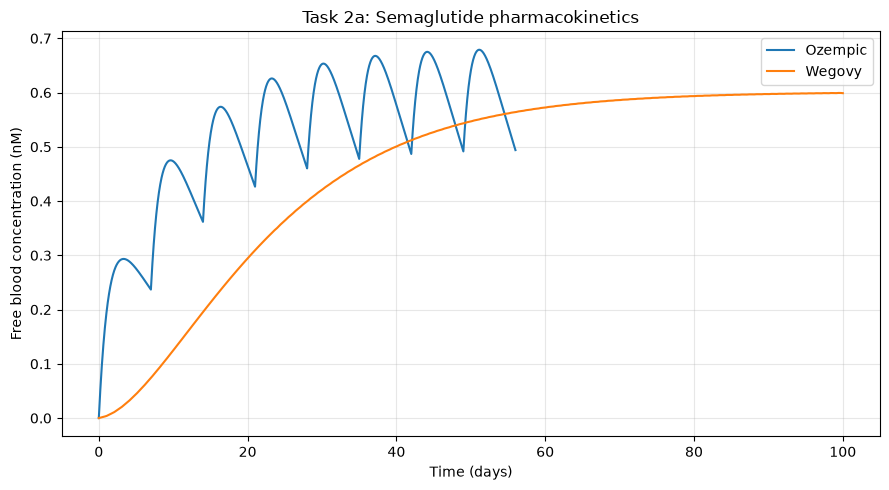

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Shared model parameters from the instructor's code
ke = 0.0039     # elimination rate, 1/h
V = 10.8        # blood distribution volume, L
MW = 4113.6     # molecular weight, g/mol
Ffree = 0.01    # fraction of blood drug that is free

products = {
    "Ozempic": {
        "Favailable": 0.89,
        "ka": 0.029,
        "D": 2.0,
        "interval": 168,
        "n_doses": 8
    },
    "Wegovy": {
        "Favailable": 0.01,
        "ka": 0.0029,
        "D": 25,
        "interval": 24,
        "n_doses": 100
    }
}

def ODEfunc(t, y, ka):
    Asc, Cc = y

    dAsc = -ka * Asc
    dCc = ka * Asc / V - ke * Cc

    return [dAsc, dCc]

def simulate(p):
    t_out = []
    Asc_out = []
    Cc_out = []

    # Initially, no drug at the absorption site or in blood
    y = np.array([0.0, 0.0])

    for i in range(p["n_doses"]):
        # Add the next dose to the absorption site
        y[0] += p["Favailable"] * p["D"]

        t0 = i * p["interval"]
        t1 = t0 + p["interval"]

        # Times at which we want the results reported
        t_eval = np.linspace(t0, t1, 241)

        sol = solve_ivp(
            ODEfunc,
            (t0, t1),
            y,
            args=(p["ka"],),
            t_eval=t_eval,
            rtol=1e-8,
            atol=1e-10
        )

        if not sol.success:
            raise RuntimeError(sol.message)

        t_out.append(sol.t)
        Asc_out.append(sol.y[0])
        Cc_out.append(sol.y[1])

        # Preserve the remaining drug for the next dosing interval
        y = sol.y[:, -1].copy()

    t = np.concatenate(t_out)
    Asc = np.concatenate(Asc_out)
    Cc = np.concatenate(Cc_out)

    # Convert total blood concentration from mg/L to nM
    Cc_nM = Cc * 1e6 / MW

    # Only the free fraction is used for the target concentration
    Cfree_nM = Ffree * Cc_nM

    return t, Asc, Cfree_nM

plt.figure(figsize=(9, 5))

for name, p in products.items():
    t, Asc, Cfree = simulate(p)
    plt.plot(t / 24, Cfree, label=name)

plt.xlabel("Time (days)")
plt.ylabel("Free blood concentration (nM)")
plt.title("Task 2a: Semaglutide pharmacokinetics")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Ozempic produces noticeable weekly peaks and troughs, while the modeled daily Wegovy regimen produces a smoother concentration profile. Both regimens show drug accumulation with repeated dosing. The original settings simulate Ozempic for 56 days and Wegovy for 100 days, so the curves end at different times.

### Task 2b: Add Cavalitide with Faster Absorption

We added Cavalitide using the oral dosing parameters and increased the absorption rate constant from 0.0029 to 0.006 1/h. Because no other Cavalitide parameters were provided, we assumed its bioavailability, elimination rate, distribution volume, molecular weight, and free fraction were unchanged from the oral example. The dose remained 25 mg every 24 hours for 100 doses.

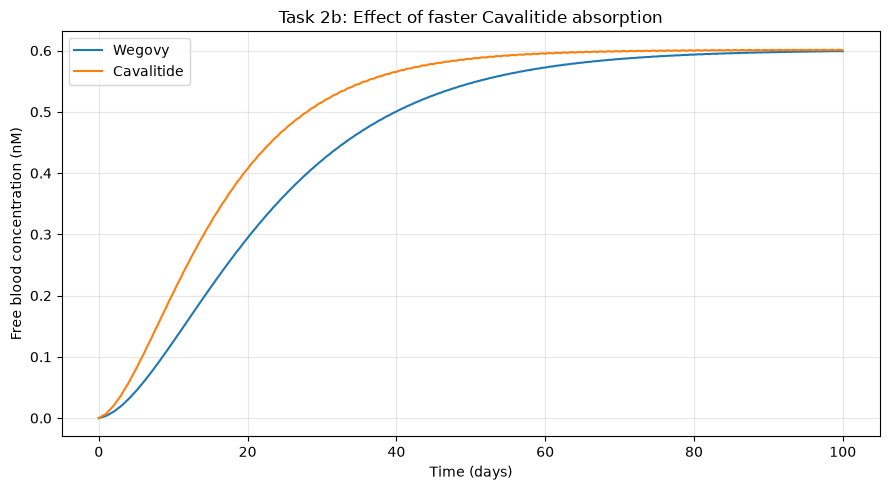

In [3]:
# Assume all other Cavalitide parameters equal the oral example
products["Cavalitide"] = products["Wegovy"].copy()
products["Cavalitide"]["ka"] = 0.006

plt.figure(figsize=(9, 5))

for name in ["Wegovy", "Cavalitide"]:
    t, Asc, Cfree = simulate(products[name])
    plt.plot(t / 24, Cfree, label=name)

plt.xlabel("Time (days)")
plt.ylabel("Free blood concentration (nM)")
plt.title("Task 2b: Effect of faster Cavalitide absorption")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Cavalitide approaches its long-term concentration pattern faster because of its higher absorption rate. However, faster absorption does not increase bioavailability. With the same bioavailability, dose, and elimination rate, the two oral regimens have the same average steady-state concentration, approximately 0.601 nM.

### Task 2c: Adjust the Code to Approach 0.5 nM

We reduced the Cavalitide dose while keeping daily administration and the absorption rate constant of 0.006 1/h. In this linear model, average steady-state concentration is proportional to dose.

The average steady-state free concentration is:

Cfree_ss = Ffree × Favailable × D × 10^6 / (ke × V × interval × MW)

Solving for a target concentration of 0.5 nM gives a dose of approximately 20.79 mg every 24 hours.

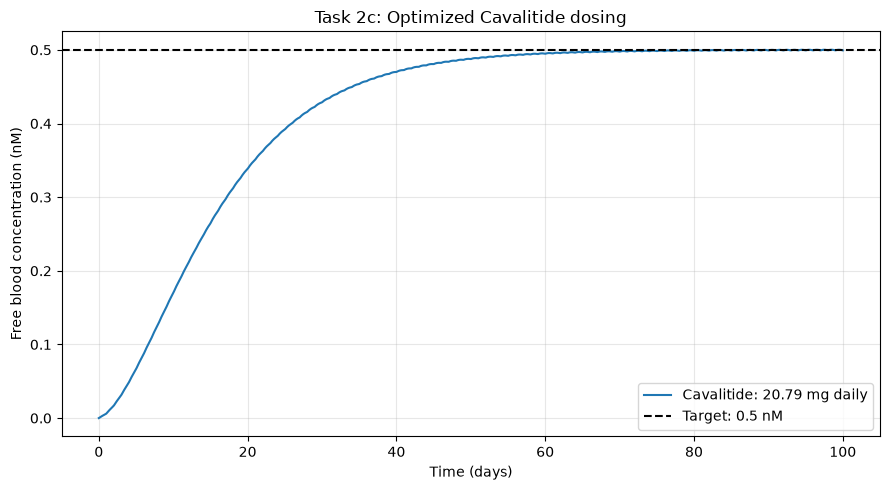

Optimized dose: 20.79 mg every 24 hours
Final-day minimum: 0.4993 nM
Final-day maximum: 0.5002 nM


In [4]:
target = 0.5  # target free blood concentration, nM

# Copy the Cavalitide regimen
optimized = products["Cavalitide"].copy()

# Calculate the dose needed for an average of 0.5 nM
optimized["D"] = (
    target * ke * V * optimized["interval"] * MW
    / (Ffree * optimized["Favailable"] * 1e6)
)

# Simulate the optimized regimen
t, Asc, Cfree = simulate(optimized)

plt.figure(figsize=(9, 5))
plt.plot(
    t / 24,
    Cfree,
    label=f"Cavalitide: {optimized['D']:.2f} mg daily"
)
plt.axhline(
    target,
    color="black",
    linestyle="--",
    label="Target: 0.5 nM"
)

plt.xlabel("Time (days)")
plt.ylabel("Free blood concentration (nM)")
plt.title("Task 2c: Optimized Cavalitide dosing")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Check the final daily dosing interval
last_interval = Cfree[-241:]

print(f"Optimized dose: {optimized['D']:.2f} mg every 24 hours")
print(f"Final-day minimum: {last_interval.min():.4f} nM")
print(f"Final-day maximum: {last_interval.max():.4f} nM")

Reducing the dose from 25 mg to approximately 20.79 mg daily brought the modeled free blood concentration close to the 0.5 nM target. During the final dosing interval, concentration ranged from approximately 0.4993 to 0.5002 nM.

We changed only the dose because the original daily regimen produced a concentration above the target. Daily administration maintained small concentration fluctuations. Steady state under repeated dosing is a repeating concentration pattern rather than a perfectly constant concentration.

These predictions depend on the assumed pharmacokinetic parameters and do not establish clinical safety or effectiveness.

### Additional analysis: Sensitivity to daily dose

We simulated Cavalitide doses of 15, 20.79, 25, and 30 mg daily,
holding all other parameters constant. We compared the full
100-day concentration profiles and examined the final five days
to show the daily peaks and troughs near steady state.

This analysis evaluates how dose selection affects achievement
of the 0.5 nM target.

Dose sensitivity analysis
--------------------------------------------------------------
 Dose (mg)    Minimum (nM)    Maximum (nM)    Average (nM)
     15.00          0.3602          0.3608          0.3606
     20.79          0.4993          0.5002          0.4999
     25.00          0.6004          0.6014          0.6011
     30.00          0.7204          0.7217          0.7213


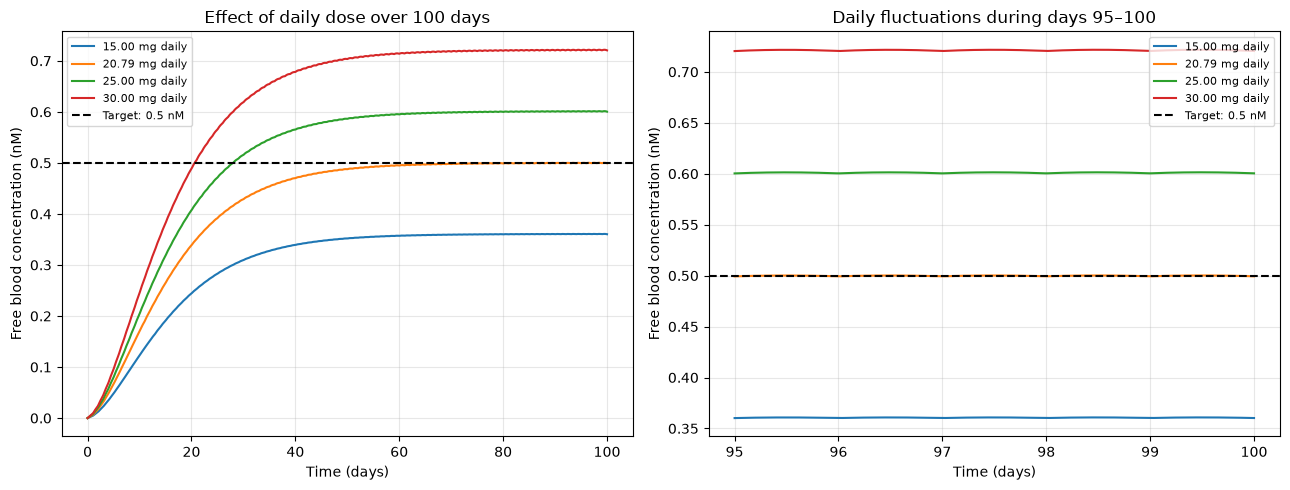

In [5]:
# Compare several doses while keeping other parameters unchanged
doses = [15, optimized["D"], 25, 30]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

print("Dose sensitivity analysis")
print("-" * 62)
print(
    f"{'Dose (mg)':>10} {'Minimum (nM)':>15} "
    f"{'Maximum (nM)':>15} {'Average (nM)':>15}"
)

for dose in doses:
    # Create a separate regimen for each dose
    p = optimized.copy()
    p["D"] = dose

    t, Asc, Cfree = simulate(p)
    days = t / 24

    # Full treatment profile
    line, = axes[0].plot(
        days, Cfree, label=f"{dose:.2f} mg daily"
    )

    # Zoom in on the final five days
    mask = days >= 95
    axes[1].plot(
        days[mask],
        Cfree[mask],
        color=line.get_color(),
        label=f"{dose:.2f} mg daily"
    )

    # Calculate statistics over the final dosing interval
    last_t = t[-241:]
    last_C = Cfree[-241:]

    # Time-weighted average using trapezoidal integration
    average = np.sum(
        0.5 * (last_C[1:] + last_C[:-1]) * np.diff(last_t)
    ) / (last_t[-1] - last_t[0])

    print(
        f"{dose:10.2f} {last_C.min():15.4f} "
        f"{last_C.max():15.4f} {average:15.4f}"
    )

for ax in axes:
    ax.axhline(
        0.5,
        color="black",
        linestyle="--",
        label="Target: 0.5 nM"
    )
    ax.set_xlabel("Time (days)")
    ax.set_ylabel("Free blood concentration (nM)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_title("Effect of daily dose over 100 days")
axes[1].set_title("Daily fluctuations during days 95–100")

plt.tight_layout()
plt.show()

The average concentration near steady state increased proportionally with daily dose, consistent with the model's linear absorption and elimination equations. The approximate final-day average concentrations were 0.361, 0.500, 0.601, and 0.721 nM for daily doses of 15, 20.79, 25, and 30 mg, respectively.

The optimized dose stayed closest to the 0.5 nM target. The zoomed graph also revealed small daily peaks and troughs, demonstrating that repeated dosing produces a periodic steady state.

These results describe sensitivity to dose under fixed model parameters. They do not account for differences in absorption elimination, or other parameters between patients.

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

TBD

## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

## AI Usage Statement:
*This is where you will provide a short description on whether AI (and which AI) was used for any of the sections above and whether it helped or why it did not help.*
- *Example statement: "We used Claude Code to generate our linear regression plot. At first, it did not include an R^2 calculation, so we added it to the code afterwards."*

## GitHub Repository Link:
*Please provide the link to your shared GitHub repository that includes this notebook and any other scripts, notebooks, or data that you used for this project.*


## References:
*You can use any format you like but provide the citations for facts that you referenced in this project notebook.*

SciPy community. *scipy.optimize.curve_fit.* SciPy documentation. https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html

World Health Organization. (2024, March 1). https://www.who.int/news/item/01-03-2024-one-in-eight-people-are-now-living-with-obesity

World Health Organization. https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight



## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*